<a href="https://colab.research.google.com/github/Rin871-tech/-primetrade-analysis/blob/main/EDA_42.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Name - Vaishnavi Chavan
Batch - TA2
TY Btech AIML

In [ ]:
import pandas as pd

# A tiny hand-made dataset to illustrate the concepts above
student_data = {
    "RollNo": [1, 2, 3, 4, 5],
    "Name":   ["Aarav", "Diya", "Kabir", "Meera", "Ishan"],
    "Age":    [19, 20, 19, 21, 20],
    "Gender": ["M", "F", "M", "F", "M"],
    "CGPA":   [8.4, 9.1, 7.8, 8.9, 7.2],
    "Placed": ["Yes", "Yes", "No", "Yes", "No"],
}

student_df = pd.DataFrame(student_data)
student_df   # displaying the DataFrame

,RollNo,Name,Age,Gender,CGPA,Placed
0,1,Aarav,19,M,8.4,Yes
1,2,Diya,20,F,9.1,Yes
2,3,Kabir,19,M,7.8,No
3,4,Meera,21,F,8.9,Yes
4,5,Ishan,20,M,7.2,No


In [ ]:

# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing (used later for scaling & encoding)
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, Normalizer,
    LabelEncoder, OneHotEncoder, OrdinalEncoder
)

# Display / plotting settings
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load all datasets we will use in this notebook
titanic  = sns.load_dataset("titanic")
iris     = sns.load_dataset("iris")
tips     = sns.load_dataset("tips")
penguins = sns.load_dataset("penguins")

print("Titanic :", titanic.shape)
print("Iris    :", iris.shape)
print("Tips    :", tips.shape)
print("Penguins:", penguins.shape)

Titanic : (891, 15)
Iris    : (150, 5)
Tips    : (244, 7)
Penguins: (344, 7)


In [ ]:
# California Housing — a larger, purely numerical dataset (fetched from scikit-learn)
from sklearn.datasets import fetch_california_housing

try:
    housing_bunch = fetch_california_housing(as_frame=True)
    housing = housing_bunch.frame
except Exception as e:
    # Fallback: if there is no internet access, build a similar synthetic dataset
    print("Could not download California Housing, generating a similar synthetic dataset instead.")
    from sklearn.datasets import make_regression
    X, y = make_regression(n_samples=2000, n_features=8, noise=15, random_state=42)
    cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
            "Population", "AveOccup", "Latitude", "Longitude"]
    housing = pd.DataFrame(X, columns=cols)
    housing["MedHouseVal"] = y

print("California Housing:", housing.shape)
housing.head()

California Housing: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
import seaborn as sns
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [ ]:
import plotly.express as px
dir(px.data)

['__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 'carshare',
 'election',
 'election_geojson',
 'experiment',
 'gapminder',
 'iris',
 'medals_long',
 'medals_wide',
 'stocks',
 'tips',
 'wind']

In [ ]:
import seaborn as sns
dir(sns)

['FacetGrid',
 'JointGrid',
 'PairGrid',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__',
 '_base',
 '_compat',
 '_core',
 '_docstrings',
 '_orig_rc_params',
 '_statistics',
 '_stats',
 'algorithms',
 'axes_style',
 'axisgrid',
 'barplot',
 'blend_palette',
 'boxenplot',
 'boxplot',
 'categorical',
 'catplot',
 'choose_colorbrewer_palette',
 'choose_cubehelix_palette',
 'choose_dark_palette',
 'choose_diverging_palette',
 'choose_light_palette',
 'clustermap',
 'cm',
 'color_palette',
 'colors',
 'countplot',
 'crayon_palette',
 'crayons',
 'cubehelix_palette',
 'dark_palette',
 'desaturate',
 'despine',
 'displot',
 'distplot',
 'distributions',
 'diverging_palette',
 'dogplot',
 'ecdfplot',
 'external',
 'get_data_home',
 'get_dataset_names',
 'heatmap',
 'histplot',
 'hls_palette',
 'husl_palette',
 'jointplot',
 'kdeplot',
 'light_palette',
 'lineplot',
 'lmplot',
 'load_dataset',
 'matrix

In [ ]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
titanic.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [ ]:
titanic.sample(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
267,1,3,male,25.0,1,0,7.7750,S,Third,man,True,NaN,Southampton,yes,False
62,0,1,male,45.0,1,0,83.4750,S,First,man,True,C,Southampton,no,False
572,1,1,male,36.0,0,0,26.3875,S,First,man,True,E,Southampton,yes,True
110,0,1,male,47.0,0,0,52.0000,S,First,man,True,C,Southampton,no,True
570,1,2,male,62.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,yes,True


In [ ]:
print("Shape (rows, columns):", titanic.shape)
print("Size (total values)  :", titanic.size)
print("Dimensions (ndim)    :", titanic.ndim)

Shape (rows, columns): (891, 15)
Size (total values)  : 13365
Dimensions (ndim)    : 2


In [ ]:
print("Columns:\n", list(titanic.columns))
print("\nIndex:", titanic.index)

Columns:
 ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Index: RangeIndex(start=0, stop=891, step=1)


In [ ]:
titanic.describe()   # summary statistics for NUMERICAL columns only

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
age = titanic["age"].dropna()   # drop missing values just for this calculation

print("Mean               :", round(age.mean(), 2))
print("Median              :", round(age.median(), 2))
print("Mode                :", age.mode()[0])
print("Variance            :", round(age.var(), 2))
print("Standard Deviation  :", round(age.std(), 2))
print("Q1 (25th percentile):", age.quantile(0.25))
print("Q3 (75th percentile):", age.quantile(0.75))
print("90th Percentile     :", age.quantile(0.90))
print("Range               :", age.max() - age.min())
print("IQR (Q3 - Q1)       :", age.quantile(0.75) - age.quantile(0.25))

Mean               : 29.7
Median              : 28.0
Mode                : 24.0
Variance            : 211.02
Standard Deviation  : 14.53
Q1 (25th percentile): 20.125
Q3 (75th percentile): 38.0
90th Percentile     : 50.0
Range               : 79.58
IQR (Q3 - Q1)       : 17.875


In [ ]:
missing_count = titanic.isnull().sum()
missing_percent = (titanic.isnull().sum() / len(titanic) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent
}).sort_values("Missing %", ascending=False)

missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing %
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


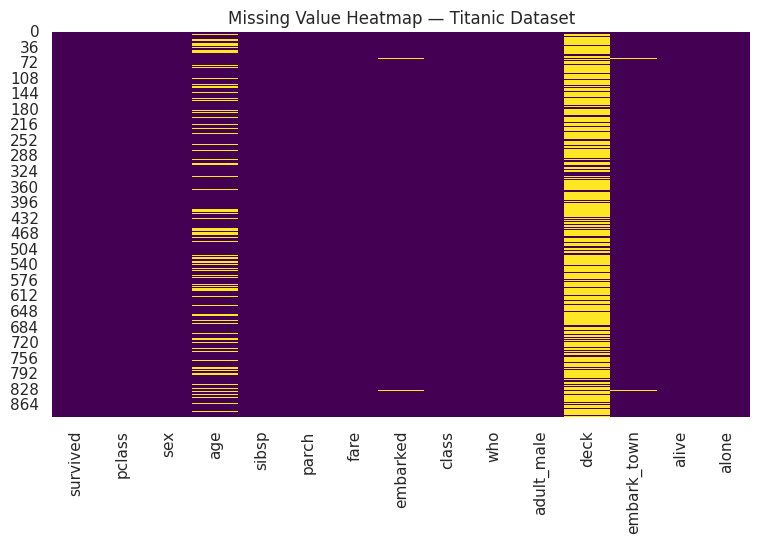

In [ ]:
# Visualization 1: Heatmap of missing values
plt.figure(figsize=(9, 5))
sns.heatmap(titanic.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap — Titanic Dataset")
plt.show()

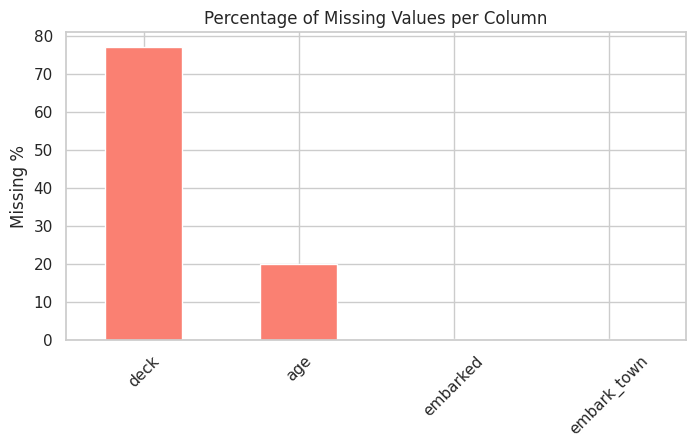

In [ ]:
# Visualization 2: Bar chart of missing value percentage
plt.figure(figsize=(8, 4))
missing_summary[missing_summary["Missing Count"] > 0]["Missing %"].plot(kind="bar", color="salmon")
plt.ylabel("Missing %")
plt.title("Percentage of Missing Values per Column")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df_demo = titanic.copy()   # always work on a COPY, never the original!

# 1. Drop rows with any missing value (use sparingly — can lose a lot of data)
df_drop = df_demo.dropna()
print("After dropna():", df_drop.shape)

# 2. Fill numerical column with MEAN
df_demo["age_mean_filled"] = df_demo["age"].fillna(df_demo["age"].mean())

# 3. Fill numerical column with MEDIAN (better when data is skewed / has outliers)
df_demo["age_median_filled"] = df_demo["age"].fillna(df_demo["age"].median())

# 4. Fill categorical column with MODE (most frequent value)
df_demo["embarked_mode_filled"] = df_demo["embarked"].fillna(df_demo["embarked"].mode()[0])

# 5. Forward Fill — carry the previous valid value forward
df_demo["age_ffill"] = df_demo["age"].ffill()

# 6. Backward Fill — carry the next valid value backward
df_demo["age_bfill"] = df_demo["age"].bfill()

# 7. Interpolation — estimate missing values using surrounding data
df_demo["age_interpolated"] = df_demo["age"].interpolate()

# 8. Fill with a CONSTANT value
df_demo["deck_constant_filled"] = df_demo["deck"].astype("object").fillna("Unknown")

df_demo[["age", "age_mean_filled", "age_median_filled",
         "age_ffill", "age_bfill", "age_interpolated"]].head(8)

After dropna(): (182, 15)


,age,age_mean_filled,age_median_filled,age_ffill,age_bfill,age_interpolated
0,22.0,22.000000,22.0,22.0,22.0,22.0
1,38.0,38.000000,38.0,38.0,38.0,38.0
2,26.0,26.000000,26.0,26.0,26.0,26.0
3,35.0,35.000000,35.0,35.0,35.0,35.0
4,35.0,35.000000,35.0,35.0,35.0,35.0
5,NaN,29.699118,28.0,35.0,54.0,44.5
6,54.0,54.000000,54.0,54.0,54.0,54.0
7,2.0,2.000000,2.0,2.0,2.0,2.0


In [ ]:
print("Number of duplicate rows in Titanic:", titanic.duplicated().sum())

# Let's create an artificial example to see duplicates in action
demo = titanic.head(5).copy()
demo = pd.concat([demo, demo.iloc[[0, 2]]], ignore_index=True)  # manually duplicate 2 rows
print("\nDemo dataset shape (with duplicates):", demo.shape)
print("Duplicate rows found:", demo.duplicated().sum())

demo[demo.duplicated(keep=False)]   # show all copies of duplicated rows

Number of duplicate rows in Titanic: 107

Demo dataset shape (with duplicates): (7, 15)
Duplicate rows found: 2


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
5,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
6,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True


In [ ]:
print("Unique classes in 'pclass':", titanic["pclass"].unique())
print("Number of unique classes  :", titanic["pclass"].nunique())

print("\nValue counts for 'embarked':")
print(titanic["embarked"].value_counts())

print("\nValue counts (as %) for 'sex':")
print(titanic["sex"].value_counts(normalize=True).round(3) * 100)

Unique classes in 'pclass': [3 1 2]
Number of unique classes  : 3

Value counts for 'embarked':
embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Value counts (as %) for 'sex':
sex
male      64.8
female    35.2
Name: proportion, dtype: float64


In [ ]:
numeric_titanic = titanic.select_dtypes(include=np.number)
corr_matrix = numeric_titanic.corr()
corr_matrix

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


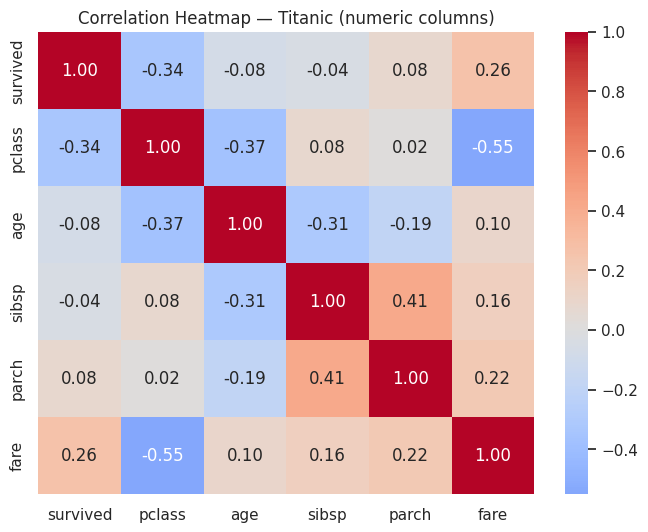

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Titanic (numeric columns)")
plt.show()

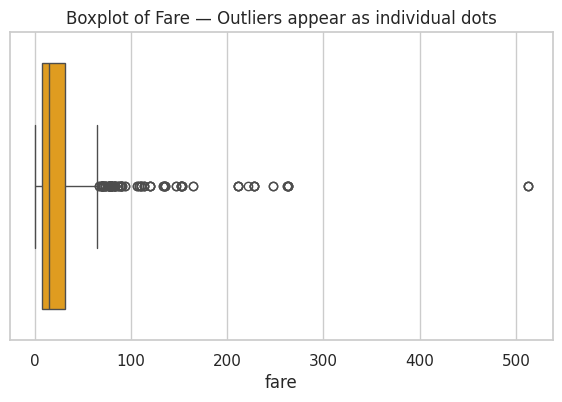

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=titanic["fare"], color="orange")
plt.title("Boxplot of Fare — Outliers appear as individual dots")
plt.show()

In [ ]:
Q1 = titanic["fare"].quantile(0.25)
Q3 = titanic["fare"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = titanic[(titanic["fare"] < lower_bound) | (titanic["fare"] > upper_bound)]
print(f"Lower bound: {lower_bound:.2f}   Upper bound: {upper_bound:.2f}")
print("Number of outliers in 'fare':", outliers.shape[0])

Lower bound: -26.72   Upper bound: 65.63
Number of outliers in 'fare': 116


In [ ]:
from scipy import stats

fare_no_na = titanic["fare"].dropna()
z_scores = np.abs(stats.zscore(fare_no_na))

z_outliers = fare_no_na[z_scores > 3]     # points more than 3 std-devs from the mean
print("Number of outliers using Z-score (|z| > 3):", z_outliers.shape[0])

Number of outliers using Z-score (|z| > 3): 20


In [ ]:
titanic_no_outliers = titanic[(titanic["fare"] >= lower_bound) & (titanic["fare"] <= upper_bound)]
print("Original shape :", titanic.shape)
print("After removing fare outliers:", titanic_no_outliers.shape)

Original shape : (891, 15)
After removing fare outliers: (775, 15)


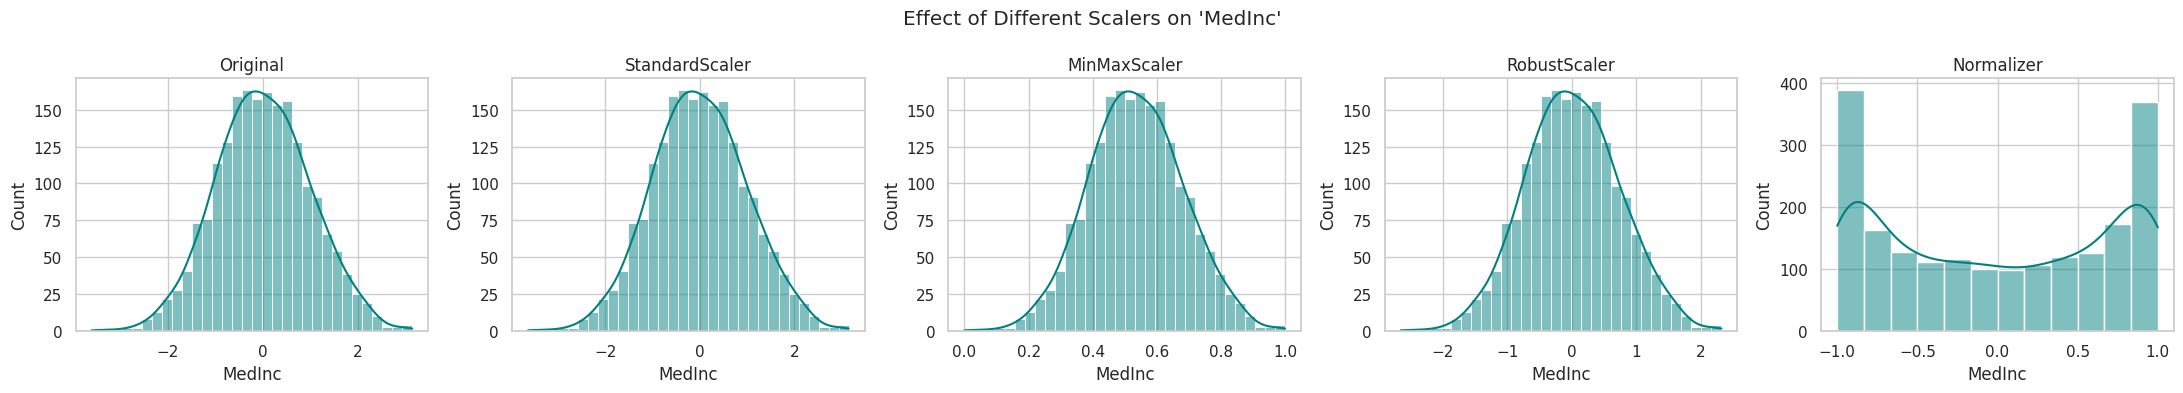

In [ ]:
housing_num = housing.select_dtypes(include=np.number).dropna()
sample_cols = housing_num.columns[:2]   # take 2 numeric columns to compare visually

scalers = {
    "Original":        housing_num[sample_cols],
    "StandardScaler":  pd.DataFrame(StandardScaler().fit_transform(housing_num[sample_cols]), columns=sample_cols),
    "MinMaxScaler":    pd.DataFrame(MinMaxScaler().fit_transform(housing_num[sample_cols]),   columns=sample_cols),
    "RobustScaler":    pd.DataFrame(RobustScaler().fit_transform(housing_num[sample_cols]),   columns=sample_cols),
    "Normalizer":      pd.DataFrame(Normalizer().fit_transform(housing_num[sample_cols]),     columns=sample_cols),
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, data) in zip(axes, scalers.items()):
    sns.histplot(data[sample_cols[0]], ax=ax, kde=True, color="teal")
    ax.set_title(name)
plt.suptitle(f"Effect of Different Scalers on '{sample_cols[0]}'")
plt.tight_layout()
plt.show()

In [ ]:
demo_enc = titanic[["sex", "embarked", "pclass"]].dropna().copy()

# 1. Label Encoding — assigns each category an integer (0, 1, 2, ...)
le = LabelEncoder()
demo_enc["sex_label"] = le.fit_transform(demo_enc["sex"])

# 2. One-Hot Encoding — creates a separate 0/1 column for every category
one_hot = pd.get_dummies(demo_enc["embarked"], prefix="embarked")

# 3. Ordinal Encoding — like Label Encoding, but you CONTROL the order
#    (pclass 1 = best, 3 = worst, so we keep that natural order)
ordinal = OrdinalEncoder(categories=[[1, 2, 3]])
demo_enc["pclass_ordinal"] = ordinal.fit_transform(demo_enc[["pclass"]])

result = pd.concat([demo_enc[["sex", "sex_label"]], one_hot,
                     demo_enc[["pclass", "pclass_ordinal"]]], axis=1)
result.head()

,sex,sex_label,embarked_C,embarked_Q,embarked_S,pclass,pclass_ordinal
0,male,1,False,False,True,3,2.0
1,female,0,True,False,False,1,0.0
2,female,0,False,False,True,3,2.0
3,female,0,False,False,True,1,0.0
4,male,1,False,False,True,3,2.0


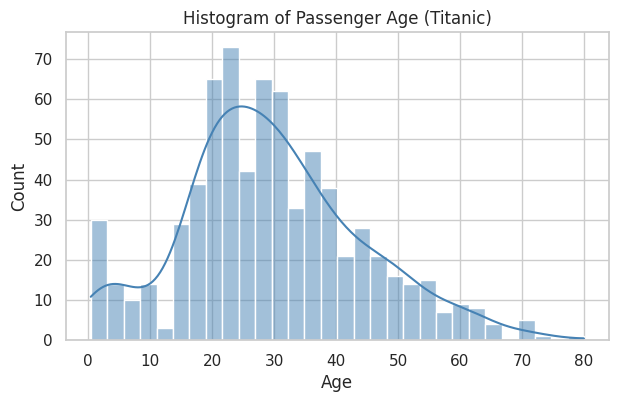

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(titanic["age"], bins=30, kde=True, color="steelblue")
plt.title("Histogram of Passenger Age (Titanic)")
plt.xlabel("Age")
plt.show()

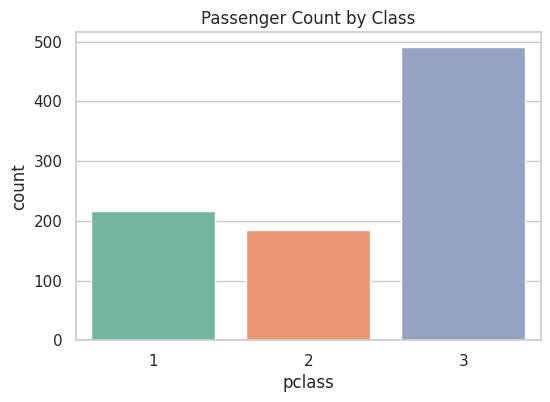

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x="pclass", data=titanic, hue="pclass", palette="Set2", legend=False)
plt.title("Passenger Count by Class")
plt.show()

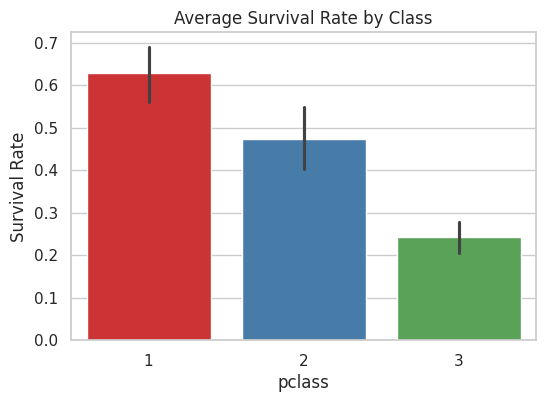

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x="pclass", y="survived", data=titanic, hue="pclass", palette="Set1", legend=False)
plt.title("Average Survival Rate by Class")
plt.ylabel("Survival Rate")
plt.show()

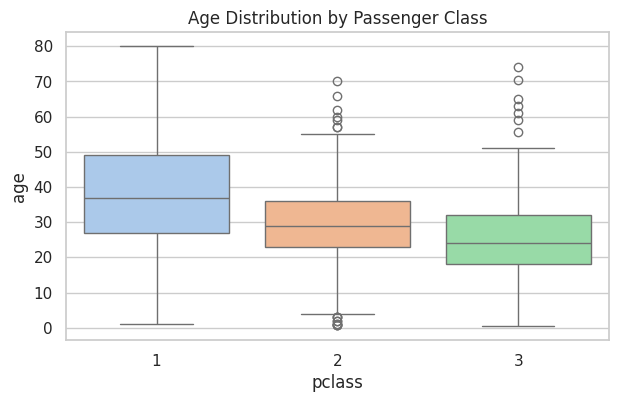

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="pclass", y="age", data=titanic, hue="pclass", palette="pastel", legend=False)
plt.title("Age Distribution by Passenger Class")
plt.show()

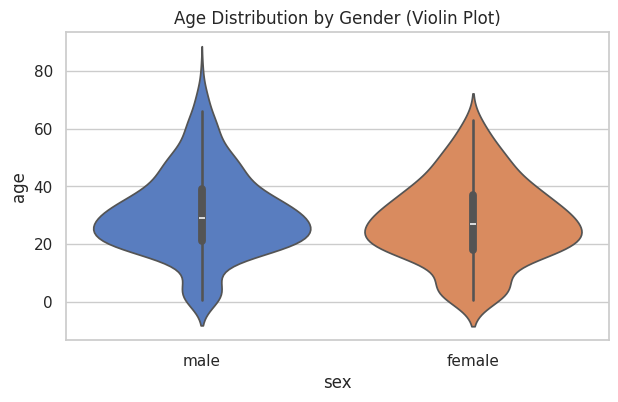

In [ ]:
plt.figure(figsize=(7, 4))
sns.violinplot(x="sex", y="age", data=titanic, hue="sex", palette="muted", legend=False)
plt.title("Age Distribution by Gender (Violin Plot)")
plt.show()

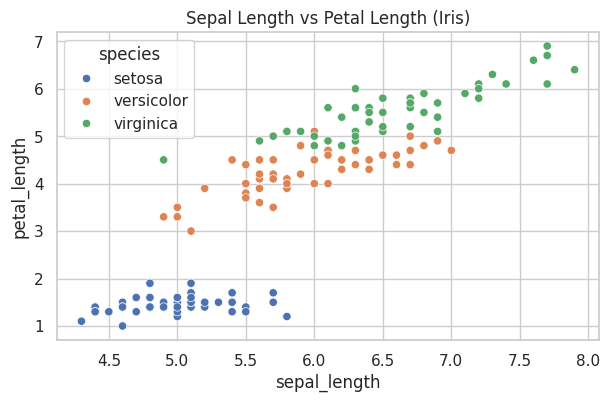

In [ ]:
plt.figure(figsize=(7, 4))
sns.scatterplot(x="sepal_length", y="petal_length", hue="species", data=iris, palette="deep")
plt.title("Sepal Length vs Petal Length (Iris)")
plt.show()

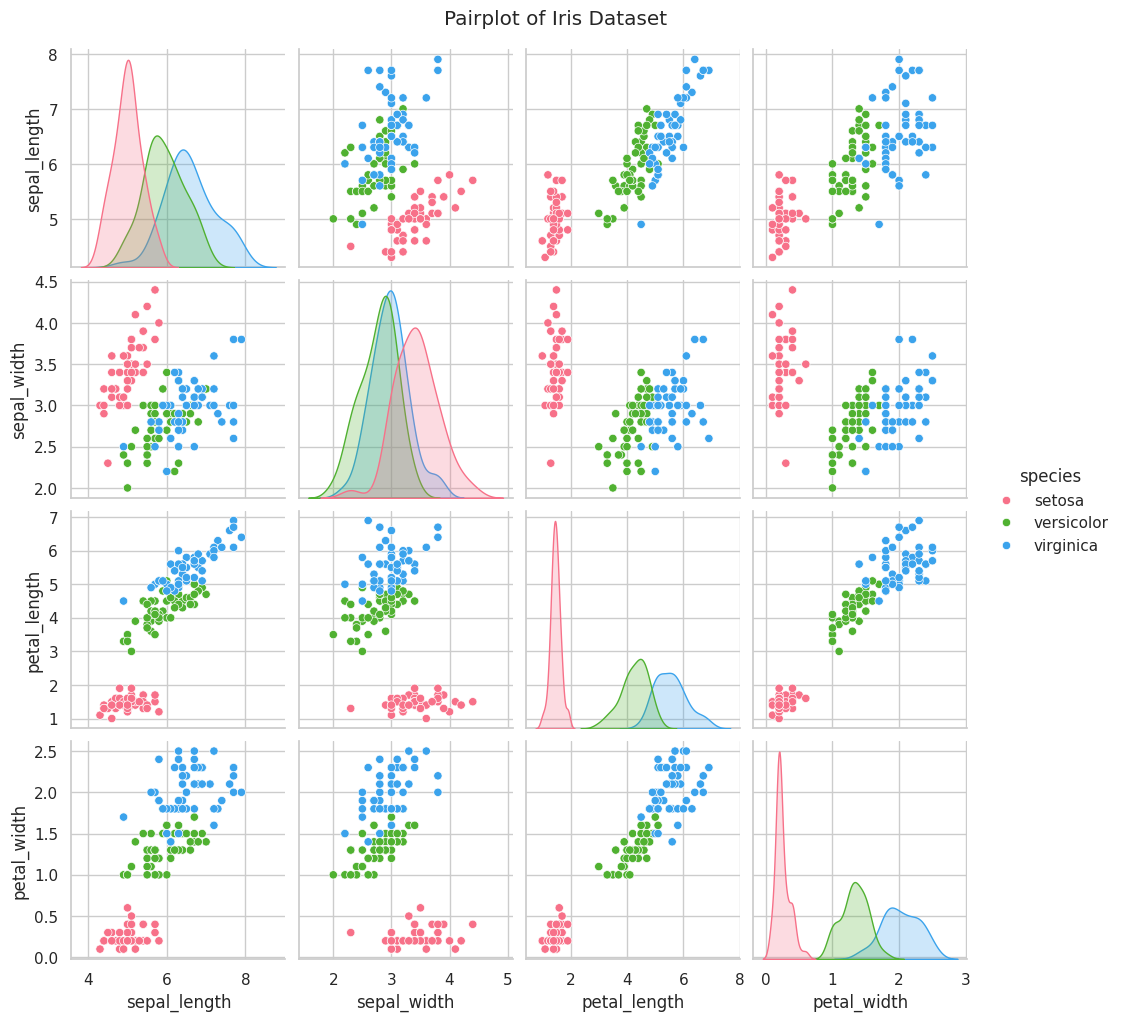

In [ ]:
sns.pairplot(iris, hue="species", palette="husl", diag_kind="kde")
plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()

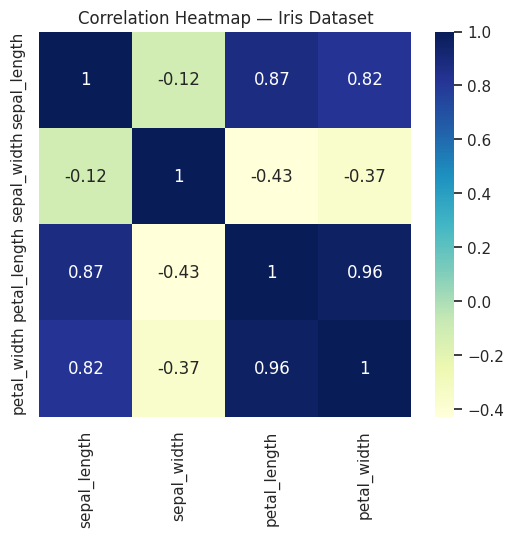

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(iris.drop(columns="species").corr(), annot=True, cmap="YlGnBu")
plt.title("Correlation Heatmap — Iris Dataset")
plt.show()

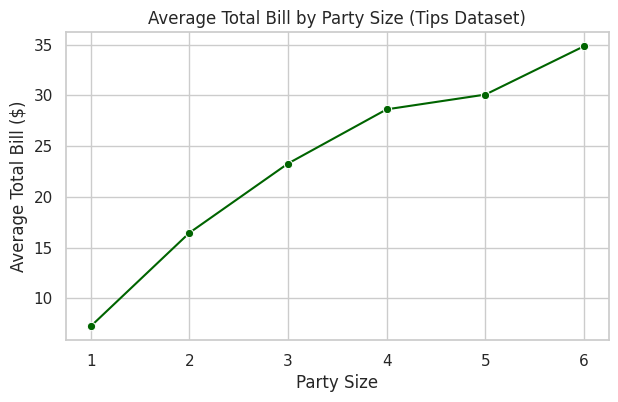

In [ ]:
bill_by_size = tips.groupby("size")["total_bill"].mean().reset_index()

plt.figure(figsize=(7, 4))
sns.lineplot(x="size", y="total_bill", data=bill_by_size, marker="o", color="darkgreen")
plt.title("Average Total Bill by Party Size (Tips Dataset)")
plt.xlabel("Party Size")
plt.ylabel("Average Total Bill ($)")
plt.show()

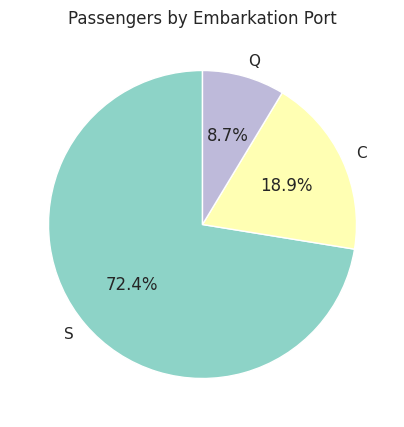

In [ ]:
plt.figure(figsize=(5, 5))
titanic["embarked"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=sns.color_palette("Set3"), startangle=90)
plt.title("Passengers by Embarkation Port")
plt.ylabel("")
plt.show()

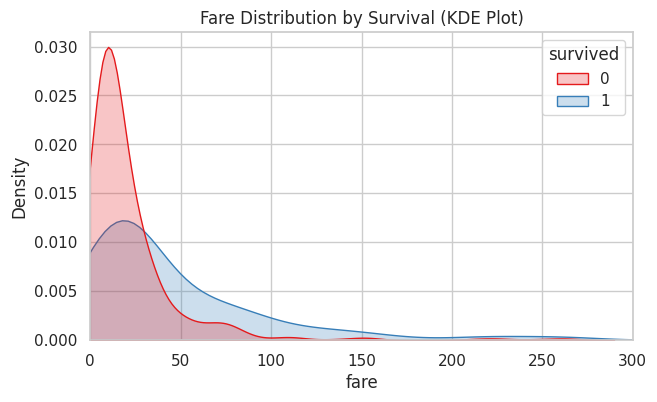

In [ ]:
plt.figure(figsize=(7, 4))
sns.kdeplot(data=titanic, x="fare", hue="survived", fill=True, common_norm=False, palette="Set1")
plt.title("Fare Distribution by Survival (KDE Plot)")
plt.xlim(0, 300)
plt.show()

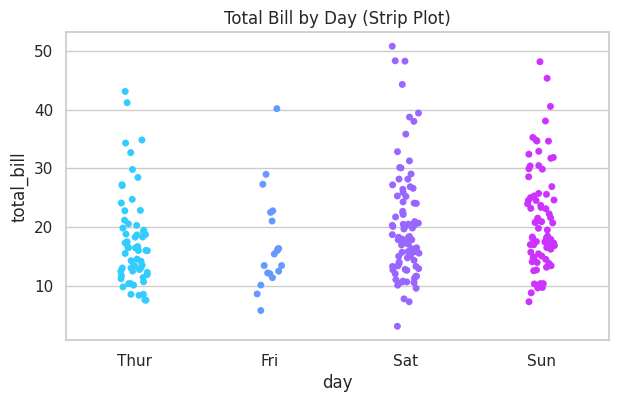

In [ ]:
plt.figure(figsize=(7, 4))
sns.stripplot(x="day", y="total_bill", data=tips, hue="day", jitter=True, palette="cool", legend=False)
plt.title("Total Bill by Day (Strip Plot)")
plt.show()

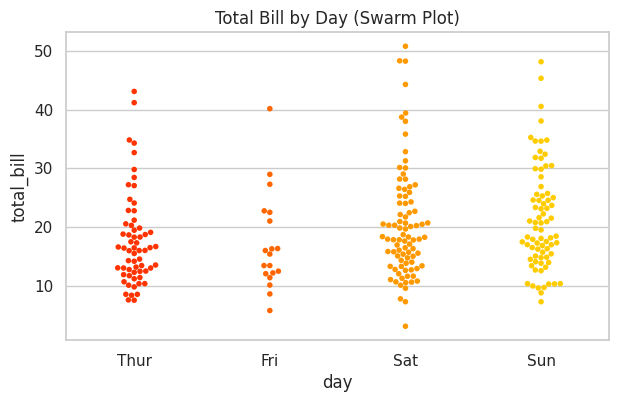

In [ ]:
plt.figure(figsize=(7, 4))
sns.swarmplot(x="day", y="total_bill", data=tips, hue="day", palette="autumn", size=4, legend=False)
plt.title("Total Bill by Day (Swarm Plot)")
plt.show()

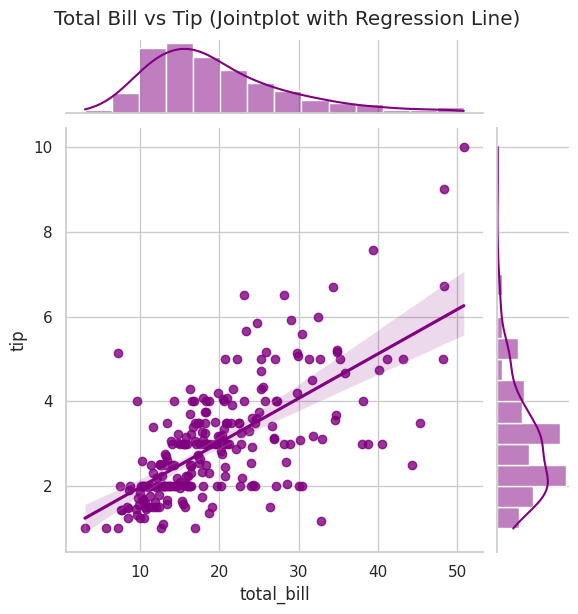

In [ ]:
sns.jointplot(x="total_bill", y="tip", data=tips, kind="reg", color="purple", height=6)
plt.suptitle("Total Bill vs Tip (Jointplot with Regression Line)", y=1.02)
plt.show()

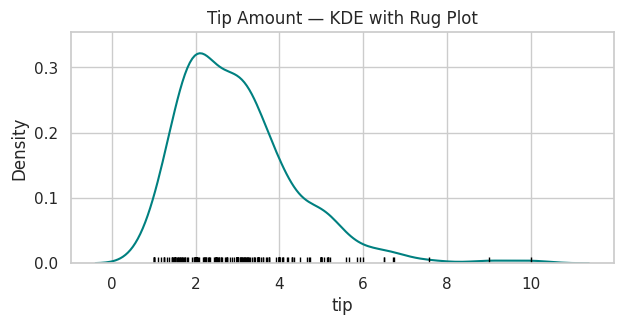

In [ ]:
plt.figure(figsize=(7, 3))
sns.kdeplot(tips["tip"], color="teal")
sns.rugplot(tips["tip"], color="black")
plt.title("Tip Amount — KDE with Rug Plot")
plt.show()

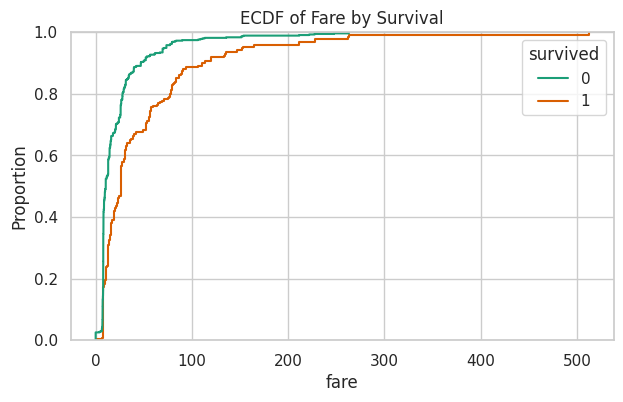

In [ ]:
plt.figure(figsize=(7, 4))
sns.ecdfplot(data=titanic, x="fare", hue="survived", palette="Dark2")
plt.title("ECDF of Fare by Survival")
plt.show()

In [ ]:
# groupby() + single aggregation
tips.groupby("day", observed=True)["total_bill"].mean()

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64

In [ ]:
# groupby() with multiple columns
tips.groupby(["day", "time"], observed=True)["tip"].mean().unstack()

time,Lunch,Dinner
day,,
Thur,2.767705,3.000000
Fri,2.382857,2.940000
Sat,NaN,2.993103
Sun,NaN,3.255132


In [ ]:
# pivot_table() — similar to groupby, but in a spreadsheet-like format
pd.pivot_table(tips, values="total_bill", index="day", columns="time",
                aggfunc="mean", observed=True)

time,Lunch,Dinner
day,,
Thur,17.664754,18.780000
Fri,12.845714,19.663333
Sat,NaN,20.441379
Sun,NaN,21.410000


In [ ]:
# crosstab() — frequency table between two categorical columns
pd.crosstab(titanic["pclass"], titanic["survived"], margins=True)

survived,0,1,All
pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


In [ ]:
# Start fresh with a clean copy
clean_df = titanic.copy()
print("Starting shape:", clean_df.shape)
clean_df.head()

Starting shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# 'age' -> fill with median (skewed, has outliers)
clean_df["age"] = clean_df["age"].fillna(clean_df["age"].median())

# 'embarked' -> fill with mode (categorical, very few missing)
clean_df["embarked"] = clean_df["embarked"].fillna(clean_df["embarked"].mode()[0])

# 'deck' -> too many missing (~77%) -> drop the column entirely
clean_df = clean_df.drop(columns=["deck"])

# drop rows still missing anything critical (safety net)
clean_df = clean_df.dropna(subset=["embark_town"])

print("Missing values remaining:\n", clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

Missing values remaining:
 Series([], dtype: int64)


In [ ]:
before = clean_df.shape[0]
clean_df = clean_df.drop_duplicates()
after = clean_df.shape[0]
print(f"Removed {before - after} duplicate rows. New shape: {clean_df.shape}")

Removed 116 duplicate rows. New shape: (773, 14)


In [ ]:
Q1, Q3 = clean_df["fare"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

n_outliers = clean_df[(clean_df["fare"] < lower) | (clean_df["fare"] > upper)].shape[0]
print(f"Fare outliers detected: {n_outliers}")

# Cap (winsorize) rather than delete, to avoid losing too many rows
clean_df["fare"] = clean_df["fare"].clip(lower=lower, upper=upper)
print("Fare range after capping:", clean_df["fare"].min(), "-", clean_df["fare"].max())

Fare outliers detected: 100
Fare range after capping: 0.0 - 71.675


In [ ]:
# Drop redundant / high-cardinality / identifier-like columns first
clean_df = clean_df.drop(columns=["who", "adult_male", "alive", "class", "embark_town"])

# One-Hot Encode nominal columns
clean_df = pd.get_dummies(clean_df, columns=["sex", "embarked"], drop_first=True)

clean_df.head()

,survived,pclass,age,sibsp,parch,fare,alone,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,False,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False,False
2,1,3,26.0,0,0,7.9250,True,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,False,True
4,0,3,35.0,0,0,8.0500,True,True,False,True


In [ ]:
num_cols = ["age", "fare"]
scaler = StandardScaler()
clean_df[num_cols] = scaler.fit_transform(clean_df[num_cols])

clean_df[num_cols].describe().round(2)

,age,fare
count,773.00,773.00
mean,0.00,-0.00
std,1.00,1.00
min,-2.12,-1.18
25%,-0.62,-0.82
50%,-0.11,-0.46
75%,0.47,0.33
max,3.68,2.04


In [ ]:
print("Final cleaned shape:", clean_df.shape)
print("\nRemaining missing values:", clean_df.isnull().sum().sum())
clean_df.head()

Final cleaned shape: (773, 10)

Remaining missing values: 0


,survived,pclass,age,sibsp,parch,fare,alone,sex_male,embarked_Q,embarked_S
0,0,3,-0.548619,1,0,-0.851827,False,True,False,True
1,1,1,0.617360,1,0,2.019543,False,False,False,False
2,1,3,-0.257124,0,0,-0.821559,True,False,False,True
3,1,1,0.398739,1,0,1.204170,False,False,False,True
4,0,3,0.398739,0,0,-0.815954,True,True,False,True


In [ ]:
# Save the final cleaned dataset to CSV
clean_df.to_csv("titanic_cleaned.csv", index=False)
print(" Saved as 'titanic_cleaned.csv'")

✅ Saved as 'titanic_cleaned.csv'


In [ ]:
# STEP 1 (example, already solved): First look at the data
print(tips.shape)
tips.head()

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
# STEP 2: Check for missing values
# TODO: use isnull().sum() on the tips dataset
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [ ]:
# STEP 3: Check for duplicate rows
# TODO: use duplicated().sum()
tips.duplicated().sum()

np.int64(1)

In [ ]:
# STEP 4: Get summary statistics
# TODO: use describe()
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


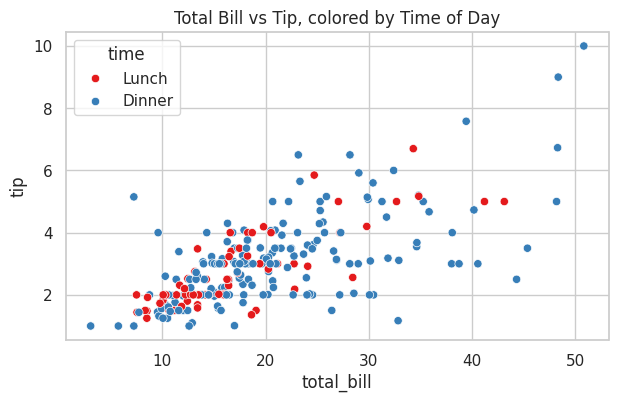

In [ ]:
# STEP 5: Visualize the relationship between total_bill and tip
# TODO: create a scatter plot, colored by 'time'
plt.figure(figsize=(7, 4))
sns.scatterplot(x="total_bill", y="tip", hue="time", data=tips, palette="Set1")
plt.title("Total Bill vs Tip, colored by Time of Day")
plt.show()

In [ ]:
# Exercise 1: Load Iris and print the first five rows
# TODO: complete this
iris_ex = sns.load_dataset("iris")
print(iris_ex.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [ ]:
# Exercise 2: Find missing values in the Titanic dataset
# TODO: complete this
print(titanic.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [ ]:
# Exercise 3: Remove duplicate rows from the Tips dataset (if any)
# TODO: complete this
tips_no_dup = tips.drop_duplicates()
print("Before:", tips.shape, "After:", tips_no_dup.shape)

Before: (244, 7) After: (243, 7)


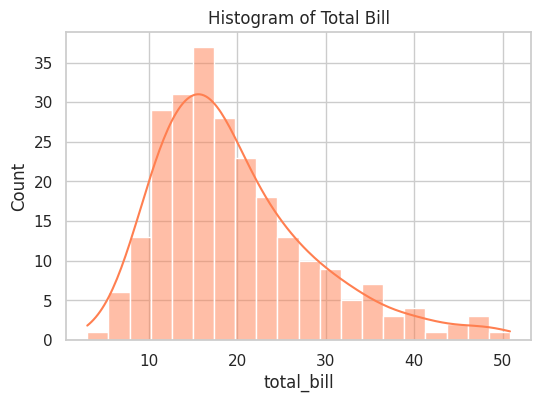

In [ ]:
# Exercise 4: Plot a histogram of the 'total_bill' column from Tips
# TODO: complete this
plt.figure(figsize=(6, 4))
sns.histplot(tips["total_bill"], bins=20, kde=True, color="coral")
plt.title("Histogram of Total Bill")
plt.show()

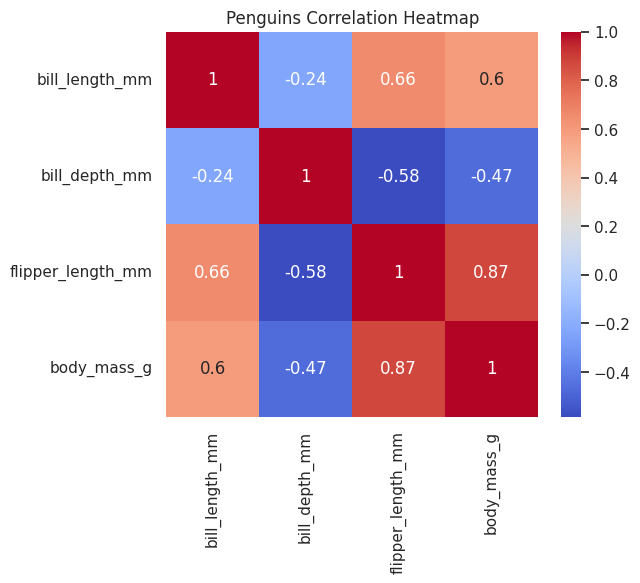

In [ ]:
# Exercise 5: Create a correlation heatmap for the Penguins dataset
# TODO: complete this
plt.figure(figsize=(6, 5))
sns.heatmap(penguins.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm")
plt.title("Penguins Correlation Heatmap")
plt.show()

LOADING PENGUINS DATASET

Dataset loaded successfully!
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  

1. DATASET SHAPE

Number of rows: 344
Number of columns: 7

Dataset shape: (344, 7)

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

2. MISSING VALUES ANALYSIS

Missing values per column:
           Column  Missing_Count  Percentage
          species              0    0.000000
    

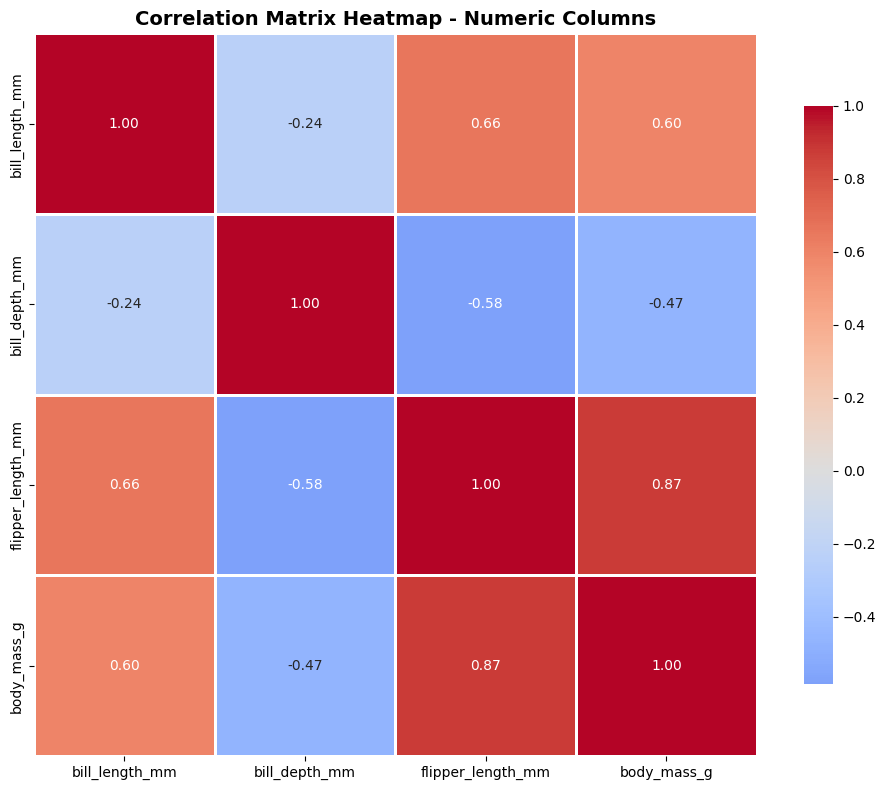


✓ Heatmap saved as '04_correlation_heatmap.png'

5. BOXPLOT: BILL LENGTH BY SPECIES


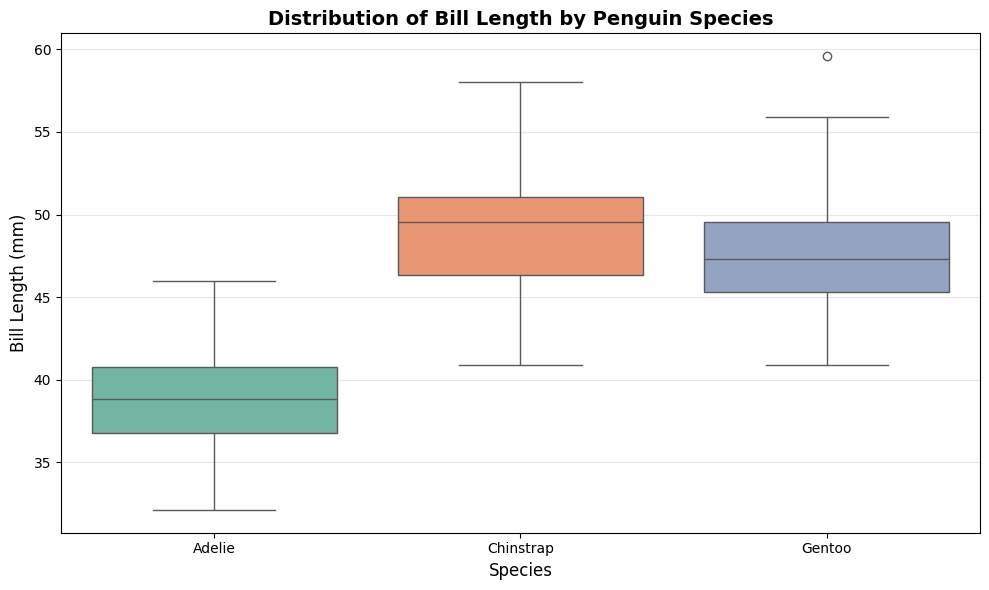


✓ Boxplot saved as '05_boxplot_bill_length.png'

Bill Length Statistics by Species:
           count       mean       std   min    25%    50%     75%   max
species                                                                
Adelie     151.0  38.791391  2.663405  32.1  36.75  38.80  40.750  46.0
Chinstrap   68.0  48.833824  3.339256  40.9  46.35  49.55  51.075  58.0
Gentoo     123.0  47.504878  3.081857  40.9  45.30  47.30  49.550  59.6

6. PAIRPLOT COLORED BY SPECIES


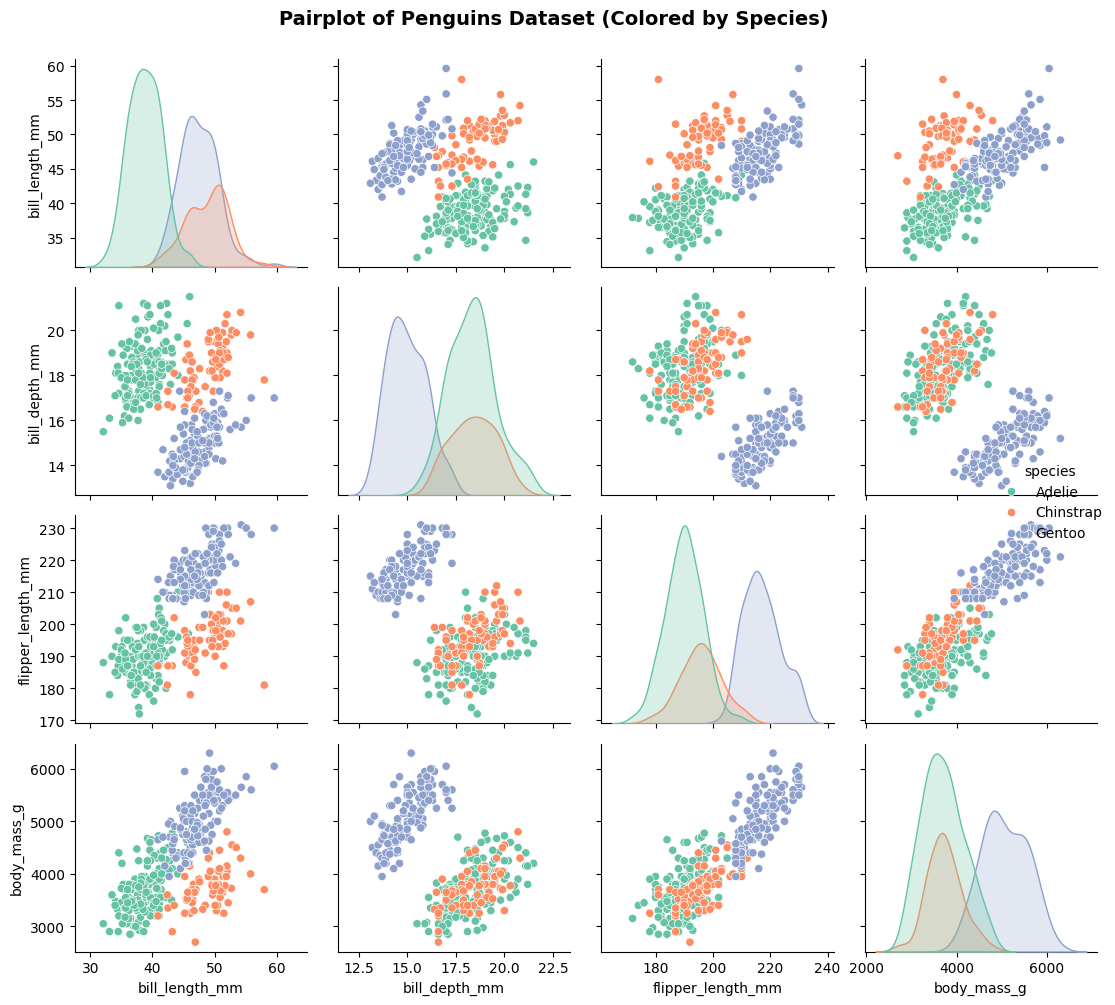


✓ Pairplot saved as '06_pairplot.png'

7. CLEANED DATASET

Cleaning steps:
  Original dataset shape: (344, 7)

  Step 1: Handling missing values
    - Removing rows with any missing values...
    - Rows removed due to missing values: 11

  Step 2: Removing duplicate rows
    - Number of duplicates found: 0
    - Duplicates removed (if any)

  ✓ Final cleaned dataset shape: (333, 7)
  ✓ Total rows removed: 11
  ✓ Total columns: 7

Cleaned Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
dtypes:

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [7]:
# Your Mini Assignment code goes here
"""
Mini Assignment: Complete EDA on the Penguins Dataset
This script performs a full exploratory data analysis including:
1. Dataset shape
2. Missing values analysis
3. Duplicate rows detection
4. Correlation matrix and heatmap
5. Boxplot by species
6. Pairplot colored by species
7. Fully cleaned dataset
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import load_dataset

# ============================================================================
# LOAD THE DATASET
# ============================================================================
print("="*70)
print("LOADING PENGUINS DATASET")
print("="*70)

penguins = load_dataset('penguins')
print("\nDataset loaded successfully!")
print(penguins.head())

# ============================================================================
# 1. NUMBER OF ROWS AND COLUMNS
# ============================================================================
print("\n" + "="*70)
print("1. DATASET SHAPE")
print("="*70)

rows, cols = penguins.shape
print(f"\nNumber of rows: {rows}")
print(f"Number of columns: {cols}")
print(f"\nDataset shape: {penguins.shape}")
print(f"\nColumn names:\n{penguins.columns.tolist()}")

# ============================================================================
# 2. NUMBER OF MISSING VALUES (PER COLUMN)
# ============================================================================
print("\n" + "="*70)
print("2. MISSING VALUES ANALYSIS")
print("="*70)

missing_values = penguins.isnull().sum()
missing_percent = (missing_values / len(penguins)) * 100

missing_df = pd.DataFrame({
    'Column': missing_values.index,
    'Missing_Count': missing_values.values,
    'Percentage': missing_percent.values
})

print("\nMissing values per column:")
print(missing_df.to_string(index=False))
print(f"\nTotal missing values in dataset: {penguins.isnull().sum().sum()}")

# ============================================================================
# 3. NUMBER OF DUPLICATE ROWS
# ============================================================================
print("\n" + "="*70)
print("3. DUPLICATE ROWS ANALYSIS")
print("="*70)

duplicates = penguins.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

if duplicates > 0:
    print("\nDuplicate rows:")
    print(penguins[penguins.duplicated(keep=False)].sort_values(by=list(penguins.columns)))
else:
    print("No duplicate rows found!")

# ============================================================================
# 4. CORRELATION MATRIX & HEATMAP
# ============================================================================
print("\n" + "="*70)
print("4. CORRELATION MATRIX & HEATMAP")
print("="*70)

# Select only numeric columns
numeric_cols = penguins.select_dtypes(include=[np.number]).columns
correlation_matrix = penguins[numeric_cols].corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)

# Create heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix Heatmap - Numeric Columns', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/04_correlation_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n✓ Heatmap saved as '04_correlation_heatmap.png'")

# ============================================================================
# 5. BOXPLOT: BILL_LENGTH_MM BY SPECIES
# ============================================================================
print("\n" + "="*70)
print("5. BOXPLOT: BILL LENGTH BY SPECIES")
print("="*70)

plt.figure(figsize=(10, 6))
sns.boxplot(data=penguins, x='species', y='bill_length_mm', hue='species', palette='Set2', legend=False)
plt.title('Distribution of Bill Length by Penguin Species', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Bill Length (mm)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/content/05_boxplot_bill_length.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n✓ Boxplot saved as '05_boxplot_bill_length.png'")

# Print summary statistics
print("\nBill Length Statistics by Species:")
print(penguins.groupby('species')['bill_length_mm'].describe())

# ============================================================================
# 6. PAIRPLOT COLORED BY SPECIES
# ============================================================================
print("\n" + "="*70)
print("6. PAIRPLOT COLORED BY SPECIES")
print("="*70)

# Removed the extra plt.figure(figsize=(14, 12)) as sns.pairplot creates its own figure
pairplot = sns.pairplot(penguins, hue='species', palette='Set2',
                        diag_kind='kde', height=2.5)
pairplot.fig.suptitle('Pairplot of Penguins Dataset (Colored by Species)',
                       fontsize=14, fontweight='bold', y=1.001)
plt.tight_layout()
plt.savefig('/content/06_pairplot.png', dpi=100, bbox_inches='tight')
plt.show()
print("\n✓ Pairplot saved as '06_pairplot.png'")

# ============================================================================
# 7. FULLY CLEANED DATASET
# ============================================================================
print("\n" + "="*70)
print("7. CLEANED DATASET")
print("="*70)

# Create a copy for cleaning
penguins_cleaned = penguins.copy()

print("\nCleaning steps:")
print(f"  Original dataset shape: {penguins_cleaned.shape}")

# Step 1: Remove rows with missing values
print(f"\n  Step 1: Handling missing values")
print(f"    - Removing rows with any missing values...")
penguins_cleaned = penguins_cleaned.dropna()
print(f"    - Rows removed due to missing values: {rows - len(penguins_cleaned)}")

# Step 2: Remove duplicates
print(f"\n  Step 2: Removing duplicate rows")
print(f"    - Number of duplicates found: {penguins_cleaned.duplicated().sum()}")
penguins_cleaned = penguins_cleaned.drop_duplicates()
print(f"    - Duplicates removed (if any)")

# Step 3: Reset index
penguins_cleaned = penguins_cleaned.reset_index(drop=True)

print(f"\n  ✓ Final cleaned dataset shape: {penguins_cleaned.shape}")
print(f"  ✓ Total rows removed: {rows - len(penguins_cleaned)}")
print(f"  ✓ Total columns: {penguins_cleaned.shape[1]}")

print("\nCleaned Dataset Info:")
print(penguins_cleaned.info())

print("\nFirst few rows of cleaned dataset:")
print(penguins_cleaned.head(10))

print("\nCleaned Dataset Summary Statistics:")
print(penguins_cleaned.describe())

# Verify no missing values
print(f"\nMissing values in cleaned dataset:\n{penguins_cleaned.isnull().sum()}")
print(f"Duplicate rows in cleaned dataset: {penguins_cleaned.duplicated().sum()}")

# Save cleaned dataset
penguins_cleaned.to_csv('/content/penguins_cleaned.csv', index=False)
print("\n✓ Cleaned dataset saved as 'penguins_cleaned.csv'")

# ============================================================================
# SUMMARY REPORT
# ============================================================================
print("\n" + "="*70)
print("EDA SUMMARY REPORT")
print("="*70)

summary_report = f"""
ORIGINAL DATASET:
  • Rows: {rows}
  • Columns: {cols}
  • Total missing values: {penguins.isnull().sum().sum()}
  • Duplicate rows: {duplicates}

CLEANED DATASET:
  • Rows: {len(penguins_cleaned)}
  • Columns: {penguins_cleaned.shape[1]}
  • Total missing values: {penguins_cleaned.isnull().sum().sum()}
  • Duplicate rows: {penguins_cleaned.duplicated().sum()}
  • Rows removed: {rows - len(penguins_cleaned)}

DATA TYPES:
{penguins_cleaned.dtypes.to_string()}

SPECIES DISTRIBUTION:
{penguins_cleaned['species'].value_counts().to_string()}

KEY INSIGHTS:
  • Adelie, Chinstrap, and Gentoo penguins are well represented
  • Bill length, flipper length, and body mass vary by species
  • No missing values or duplicates in cleaned dataset
  • Numeric columns show moderate to strong correlations
"""

print(summary_report)

print("\n" + "="*70)
print("✓ EDA COMPLETE!")
print("="*70)
penguins.head()